# Agentic forecasting step-by-step

**skforecast-ai** is an **AI forecasting assistant** that pairs a deterministic engine, powered by [**skforecast**](https://skforecast.org), with an **LLM reasoning layer**. Simply provide a time series, and the assistant automatically profiles the data, selects a model using established best practices, and evaluates its performance. It returns both the final forecast and the runnable skforecast script that produced it.

This tutorial walks through the **step-by-step path**: the approach for users who want granular control to inspect or adjust intermediate decisions before committing to a full run. If you prefer a single-call workflow that returns results immediately, see the [fast-path tutorial](./agentic-forecasting.html).

Both paths share the same deterministic engine and produce identical results and reproducible `skforecast` code. The step-by-step path gives you three additional capabilities:

+ **Inspect intermediate objects**: examine the `ForecastingProfile` and `ForecastPlan` before any model is trained, and confirm the assistant's recommendations make sense for your domain.

+ **Override any single decision**: change the forecaster, the estimator and its hyperparameters, the lags, the window features, the horizon or the interval without re-running the entire pipeline from scratch. Pass the modified plan directly to `forecast()` or `backtest()`.

+ **Reuse the profile and plan across branches**: build the profile and plan once, then run `forecast()` for future predictions, `backtest()` for historical evaluation, and `compare()` to rank several candidate configurations: each reusing the same profile, with no redundant profiling.

The `ask()` method is available at every stage. It interprets what you pass to it (a profile, a plan, a generated script, a cross-validation strategy, a forecast result, a backtest result, or a comparison result), but it never executes the workflow or silently changes any recommendation.

<p align="center">
  <img src="../img/how-it-works.svg#only-light" alt="How skforecast-ai works: the fast path runs profiling and planning inside forecast() or backtest(); the step-by-step path calls profile(), plan() and create_cv() so you can inspect each object. compare() ranks several configurations under the same cross-validation, and ask() explains any object at any moment." width="100%">
  <img src="../img/how-it-works-dark.svg#only-dark" alt="How skforecast-ai works: the fast path runs profiling and planning inside forecast() or backtest(); the step-by-step path calls profile(), plan() and create_cv() so you can inspect each object. compare() ranks several configurations under the same cross-validation, and ask() explains any object at any moment." width="100%">
</p>

The following example walks through the **step-by-step path**, allowing users to understand and control what happens under the hood. If you prefer the quickest way to go from raw data to a validated forecast with minimal setup, visit the [fast-path tutorial](./agentic-forecasting.html).

## Assistant initialization

The first step is to instantiate a `ForecastingAssistant`, which will be responsible for executing the entire workflow (profiling, planning, backtesting, and forecasting), as well as explaining the outputs and suggesting improvements.

To activate the optional LLM support, users must pass a string in the format `'provider:model_name'` (for example, `'openai:gpt-5.5'`, `'google:gemini-3.8-flash'`, `'anthropic:claude-sonnet-5-5'`, or `'ollama:qwen3:8b'`). For hosted providers, the corresponding API key must be available as an environment variable or passed explicitly when creating the assistant. Your dataset is never sent: the LLM receives only metadata and summary statistics, never the raw time series values. In this tutorial, we keep `send_data_to_llm=False` (the default), so passing a result to `ask()`, whose own predictions and metrics are sent, emits a `DataSentToLLMWarning` as a reminder.

In [1]:
# Data processing
# ==============================================================================
import os
import pandas as pd
from skforecast.datasets import fetch_dataset

# Plots
# ==============================================================================
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
import plotly.offline as poff
pio.templates.default = "seaborn"
poff.init_notebook_mode(connected=True)
plt.style.use('seaborn-v0_8-darkgrid')

# skforecast and skforecast-ai
# ==============================================================================
import skforecast
import skforecast_ai
from skforecast_ai import ForecastingAssistant
from skforecast.model_selection import TimeSeriesFold
from skforecast.plot import set_dark_theme

# Python utilities
# ==============================================================================
import textwrap

color = '\033[1m\033[38;5;208m'
print(f"{color}Version skforecast_ai: {skforecast_ai.__version__}")
print(f"{color}Version skforecast: {skforecast.__version__}")

Version skforecast_ai: 0.5.0
Version skforecast: 0.27.0


<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">✏️ Note</b>
</p>

  <p>
    If you do not have access to an LLM, you can still follow the full tutorial using only the deterministic methods. Profiling, planning, backtesting, and forecasting all run without an LLM. Only the <code>ask()</code> explanations and the LLM-guided variants of <code>refine_plan()</code> and <code>create_cv()</code> require a configured LLM; their deterministic counterparts work without one.
  </p>

</div>

In [2]:
# LLM-enabled assistant
# ==============================================================================
LLM_MODEL = "anthropic:claude-sonnet-5-5"
api_key = os.getenv("ANTHROPIC_API_KEY")

assistant = ForecastingAssistant(
    llm=LLM_MODEL, api_key=api_key, send_data_to_llm=False
)

# Using AWS Bedrock
# ==============================================================================
# assistant = ForecastingAssistant(
#     llm='bedrock:eu.anthropic.claude-sonnet-4-6',
#     base_url="eu-west-1"
# )

# Assistant without LLM (deterministic only)
# ==============================================================================
# assistant = ForecastingAssistant()

Before going on, `check_llm()` reports how the configuration resolves (provider, credentials, endpoint, installed extras) without calling the model, so a missing key shows up here instead of in the first `ask()`. See [Configuring the LLM](llm-configuration.html) for the details.

In [3]:
# Check the LLM configuration
# ==============================================================================
assistant.check_llm()

                          LLM Configuration Check                           
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Check        ┃ Value                                                     ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Status       │ ok                                                        │
├──────────────┼───────────────────────────────────────────────────────────┤
│ Provider     │ anthropic                                                 │
├──────────────┼───────────────────────────────────────────────────────────┤
│ Model        │ claude-sonnet-5-5                                         │
├──────────────┼───────────────────────────────────────────────────────────┤
│ Credentials  │ explicit api_key                                          │
│              │ Explicit api_key given; the environment is not consulted. │
├──────────────┼───────────────────────────────────────────────────────────┤
│ Base URL     │ None                                                      │
├──────────────┼───────────────────────────────────────────────────────────┤
│ Dependencies │ installed                                                 │
├──────────────┼───────────────────────────────────────────────────────────┤
│ Test call    │ skipped                                                   │
└──────────────┴───────────────────────────────────────────────────────────┘

<div role="alert" style="background: rgba(255,145,0,.08); border-left: 6px solid #ff9100; border-radius: 6px; padding: 10px 12px; margin: 1em 0;">

<p style="display:flex; align-items:center; font-size:1rem; color:#ff9100; margin:0 0 6px 0; font-weight:600;">
    <span style="margin-right:6px; font-size:18px;">⚠️</span>
    <strong style="margin-right:6px; font-size:18px;">Your data stays private</strong>
</p>

<p>
Enabling an LLM never sends your time-series data to the model provider.
The assistant passes only a summary of the dataset (frequency, date range, target statistics,
missing values, significant lags) and the forecaster configuration, never the raw observations.
Results passed to <code>ask()</code> are the exception: their own predictions and metrics are
sent, because a question about a result cannot be answered from summary statistics alone, and a
<code>DataSentToLLMWarning</code> reminds you of it. Pass <code>send_data_to_llm=True</code> to
acknowledge it and silence the warning. See
<a href="llm-configuration.html#what-is-sent-to-the-llm">What is sent to the LLM</a> for the full list.
</p>

</div>

## Data

The data used in this tutorial represent the hourly usage of the bike share system in the city of Washington, D.C. during the years 2011 and 2012. In addition to the number of users per hour, information about weather conditions and holidays is available.

In [4]:
# Downloading data
# ==============================================================================
data = fetch_dataset('bike_sharing', raw=True)
data = data[['date_time', 'users', 'holiday', 'weather', 'temp']]
data['date_time'] = pd.to_datetime(data['date_time'])
data.head()

╭───────────────────────────────────────────────── bike_sharing ──────────────────────────────────────────────────╮
│ Description:                                                                                                    │
│ Hourly usage of the bike share system in the city of Washington D.C. during the years 2011 and 2012. In         │
│ addition to the number of users per hour, information about weather conditions and holidays is available.       │
│                                                                                                                 │
│ Source:                                                                                                         │
│ Fanaee-T,Hadi. (2013). Bike Sharing Dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894.  │
│                                                                                                                 │
│ URL:                                                                                                            │
│ https://raw.githubusercontent.com/skforecast/skforecast-datasets/main/data/bike_sharing_dataset_clean.csv       │
│                                                                                                                 │
│ Shape: 17544 rows x 12 columns                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

,date_time,users,holiday,weather,temp
0,2011-01-01 00:00:00,16.0,0.0,clear,9.84
1,2011-01-01 01:00:00,40.0,0.0,clear,9.02
2,2011-01-01 02:00:00,32.0,0.0,clear,9.02
3,2011-01-01 03:00:00,13.0,0.0,clear,9.84
4,2011-01-01 04:00:00,1.0,0.0,clear,9.84


<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">✏️ Note</b>
</p>

  <p>
    <code>skforecast-ai</code> is ready to preprocess the data, but it is recommended that users apply their own preprocessing steps before using the assistant. This ensures the data is in the desired format and any necessary transformations have been applied before proceeding with the forecasting workflow.
  </p>

</div>

In [5]:
# Interactive plot of time series
# ==============================================================================
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=data['date_time'], y=data['users'], mode='lines', name='Users')
)
fig.update_layout(
    title  = 'Number of users',
    xaxis_title="Time",
    yaxis_title="Users",
    width=800,
    height=400,
    margin=dict(l=20, r=20, t=35, b=20),
    legend=dict(orientation="h", yanchor="top", y=1, xanchor="left", x=0.001)
)
fig.show()

For a deeper walkthrough of the exploratory analysis behind this dataset, see the skforecast example: [Forecasting time series with skforecast, XGBoost, LightGBM and CatBoost](https://cienciadedatos.net/documentos/py39-forecasting-time-series-with-skforecast-xgboost-lightgbm-catboost#Data_exploration).

## Profile the data

The `profile()` method is the first stage of the step-by-step workflow. It inspects the dataset and returns a `ForecastingProfile` object that contains:

+ **Data metadata**: detected frequency, index type, series lengths, missing values, and exogenous column roles.

+ **Modeling recommendations**: the selected forecaster family and estimator, along with alternative candidates and the reasoning behind each choice.

+ **Lag structure**: PACF-significant lags per series, used as a baseline for the planning stage.

+ **Window feature suggestions**: rolling statistics configurations appropriate for the seasonal periods implied by the frequency.

This is a purely deterministic step: no LLM is involved. The `profile` object is a prerequisite for `plan()`, and can be passed to `ask()` as `context` to have its decisions explained.

| Attribute | Description |
|---|---|
| `data_profile` | Full dataset metadata: frequency, index type, series lengths, missing values, exog columns |
| `task_type` | Family of the recommendation: `'single_series'`, `'multi_series'`, `'multivariate'`, `'statistical'` or `'foundation'` |
| `forecaster` | Recommended skforecast forecaster class name |
| `forecaster_candidates` | Ordered list of compatible forecaster names |
| `estimator` | Recommended estimator: a scikit-learn compatible estimator name, `'Arima'` for statistical tasks, or the Hugging Face model ID of the foundation model |
| `estimator_candidates` | Ordered list of compatible estimator names |
| `series_pacf` | Per-series PACF-significant lags (used by `plan()` to set default lags) |
| `window_features` | Suggested window feature configurations |
| `calendar_features` | Recommended calendar feature names derived from the frequency |
| `explanation` | Human-readable explanation of why this forecaster and estimator were selected |

In [6]:
# Profile the data
# ==============================================================================
profile = assistant.profile(
    data        = data,
    target      = 'users',
    date_column = 'date_time'
)

In [7]:
# Inspect the profile
# ==============================================================================
profile

                          Dataset Profile                          
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property       ┃ Value                                          ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Format         │ single                                         │
├────────────────┼────────────────────────────────────────────────┤
│ Series         │ 1                                              │
├────────────────┼────────────────────────────────────────────────┤
│ Observations   │ 17544                                          │
├────────────────┼────────────────────────────────────────────────┤
│ Frequency      │ h                                              │
├────────────────┼────────────────────────────────────────────────┤
│ Target         │ users                                          │
├────────────────┼────────────────────────────────────────────────┤
│ Exog columns   │ holiday, weather, temp  (categorical: weather) │
├────────────────┼────────────────────────────────────────────────┤
│ Missing values │ None                                           │
└────────────────┴────────────────────────────────────────────────┘

                                    Recommendation                                     
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property              ┃ Value                                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task type             │ single_series                                               │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Forecaster            │ ForecasterRecursive                                         │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Forecaster candidates │ ForecasterRecursive, ForecasterDirect, ForecasterFoundation │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Estimator             │ LGBMRegressor                                               │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Estimator candidates  │ LGBMRegressor, XGBRegressor, Ridge                          │
└───────────────────────┴─────────────────────────────────────────────────────────────┘

╭───────────────────────────────── Profile Explanation ──────────────────────────────────╮
│                                                                                        │
│  A single-series ML forecaster (ForecasterRecursive) is recommended. Data: 17544       │
│  observations, 'h' frequency. Alternative forecasters: ['ForecasterDirect',            │
│  'ForecasterFoundation']. Estimator: LGBMRegressor. A gradient boosting model is       │
│  preferred for a dataset of this size (17544 observations). Alternative estimators:    │
│  ['XGBRegressor', 'Ridge']. 3 exogenous variables (1 categorical) available as         │
│  predictors.                                                                           │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯

Every result also has a `describe()` method. It returns a plain-text description of the object, built by rules, without calling an LLM. It is also what `ask()` sends to the LLM about that object, so you can read it before asking.

In [8]:
# Plain-text description of the profile (no LLM involved)
# ==============================================================================
print(profile.describe())

<forecast_context>
<dataset>
- Observations: 17544
- Series: 1
- Frequency: h
- Date range: 2011-01-01 to 2012-12-31 23:00:00
- Target: users
- Exogenous columns: holiday, weather, temp
- Categorical exogenous columns: weather
- Target statistics: min 1, max 977, mean 187.8, std 181.3
- Missing values: none
- Index irregularities: none detected
</dataset>
<profile_decision>
A single-series ML forecaster (ForecasterRecursive) is recommended. Data: 17544 observations, 'h' frequency. Alternative forecasters: ['ForecasterDirect', 'ForecasterFoundation']. Estimator: LGBMRegressor. A gradient boosting model is preferred for a dataset of this size (17544 observations). Alternative estimators: ['XGBRegressor', 'Ridge']. 3 exogenous variables (1 categorical) available as predictors.
- Significant lags (partial autocorrelation, strongest first): 1, 2, 23, 22, 25, 169, 10, 145, 17, 143, 167, 19, 21, 337, 3 (first 15 of 32)
- Suggested window features: mean(window=3), std(window=3), mean(window=24

Once you have a profile, you can pass it to `ask()` as `context` to get an LLM-generated explanation of the modeling decisions. No plan is involved yet: the LLM only sees the dataset summary and the profile decisions.

Each call briefs the model with a set of **skills**, curated skforecast documents chosen from the context and the wording of the question, so the answer follows the current skforecast API. See [Skills for the LLM](./skills.html) for the list and how to choose them yourself.

In [9]:
# Ask the assistant to explain the profile
# ==============================================================================
answer = assistant.ask(
    prompt  = (
        "Explain why this forecaster and estimator were recommended for my "
        "hourly bike-sharing demand data, and what the exogenous variables add."
    ),
    context = profile,
)
answer.show_explanation()

╭────────────────────────────────── Assistant Response ──────────────────────────────────╮
│                                                                                        │
│  ForecasterRecursive was recommended because the data is a single hourly series, and   │
│  LGBMRegressor was chosen because the profile prefers a gradient boosting model for a  │
│  dataset of this size (17544 observations). The three exogenous variables (holiday,    │
│  weather, temp) are made available to the model as predictors. No results in the       │
│  context show how much they improve accuracy.                                          │
│                                                                                        │
│  Why ForecasterRecursive                                                               │
│                                                                                        │
│   • The data has 1 series (target: users) at 'h' frequency, which the profile maps to  │
│     a single-series ML forecaster.                                                     │
│   • The skforecast documentation describes ForecasterRecursive as the general-purpose  │
│     default for one series. It works with any sklearn-compatible estimator and         │
│     supports lags, window features and exogenous variables, all of which this plan     │
│     uses.                                                                              │
│   • The profile lists ForecasterDirect and ForecasterFoundation as alternatives. It    │
│     gives no further reasoning for them, so I can't say more about why they ranked     │
│     behind the recommendation.                                                         │
│                                                                                        │
│  Why LGBMRegressor                                                                     │
│                                                                                        │
│   • The profile states that a gradient boosting model is preferred for a dataset of    │
│     this size. That is the only stated reason.                                         │
│   • XGBRegressor and Ridge are listed as alternative estimators. As with the           │
│     forecasters, the context does not explain the ordering beyond that.                │
│   • The estimator and lags are set by deterministic code, so I report them as given.   │
│                                                                                        │
│  What the exogenous variables add                                                      │
│                                                                                        │
│   • Three exogenous columns are available: holiday, weather and temp. Of these,        │
│     weather is categorical.                                                            │
│   • They give the model information beyond the target's own history, which enters      │
│     through the lags and window features. The plan suggests lags such as 1, 2, 23,     │
│     22, 25 and 169, plus rolling mean and std windows.                                 │
│   • The profile also suggests calendar features: hour, day_of_week, weekend and        │
│     month.                                                                             │
│   • For forecasting, the documentation notes that exogenous values must be supplied    │
│     for every future step in the horizon.                                              │
│                                                                                        │
│  What I can't tell you                                                                 │
│                                                                                        │
│   • No feature importances are provided, so I can't say which lags, window features,   │
│     calendar features or exogenous variables contribute most.                        

## Build the plan

The `plan()` method converts the coarse modeling decisions in the `ForecastingProfile` into a fully-specified, executable configuration. It determines:

+ **Lags**: derived from the PACF-significant lags detected in the profile. You can override these explicitly.
+ **Window features**: rolling statistics configurations appropriate for the seasonal periods implied by the frequency.
+ **Preprocessing steps**: ordered list of data preparation actions (e.g., handling missing values, gaps or categorical exogenous variables).
+ **Prediction interval method**: `'bootstrapping'`, `'conformal'`, or `'native'` (selected based on the forecaster).
+ **Metrics**: the primary and secondary evaluation metrics.

Like `profile()`, this is a deterministic step. The resulting `ForecastPlan` object is the complete blueprint that `forecast()` and `backtest()` execute.

| Attribute | Description |
|---|---|
| `task_type` | Family of the plan, as in the profile, plus `'baseline'` for `ForecasterEquivalentDate` |
| `forecaster` | Forecaster class name |
| `estimator` | Estimator class name; the Hugging Face model ID for `ForecasterFoundation`; `None` for `ForecasterEquivalentDate` |
| `forecaster_kwargs` | All constructor kwargs for the forecaster, including `lags` and `window_features` |
| `estimator_kwargs` | Constructor kwargs for the estimator |
| `steps` | Forecast horizon |
| `interval` | Prediction interval quantiles, e.g. `[0.1, 0.9]` |
| `interval_method` | Method used to produce the interval (`bootstrapping`, `conformal`, or `native`) |
| `metric` | Primary metric, used to rank a comparison |
| `use_exog` | Whether exogenous variables are included |
| `overridden_fields` | Decisions you made instead of the rules; empty when every value comes from the rules |
| `preprocessing_steps` | Ordered list of preprocessing actions with code snippets |
| `explanation` | Human-readable explanation of plan decisions |

In [10]:
# Build a plan from the profile
# ==============================================================================
plan = assistant.plan(
    profile  = profile,
    steps    = 36,
    interval = [0.1, 0.9]  # 80% prediction interval
)

In [11]:
# Inspect the plan
# ==============================================================================
plan

                                      Forecast Plan                                       
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property          ┃ Value                                                              ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task type         │ single_series                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Forecaster        │ ForecasterRecursive                                                │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Estimator         │ LGBMRegressor                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Steps             │ 36                                                                 │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Frequency         │ h                                                                  │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Lags              │ [1, 2, 3, 5, 8, 10, 15, 17, 19, 20, 21, 22, 23, 24, 25, 26, 32,    │
│                   │ 33, 119, 121, 135, 136, 142, 143, 145, 160, 166, 167, 169, 313,    │
│                   │ 335, 337]                                                          │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Window features   │ [{'stats': ['mean', 'std'], 'window_size': 3}, {'stats': ['mean'], │
│                   │ 'window_size': 24}, {'stats': ['mean'], 'window_size': 168}]       │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Calendar features │ ['hour', 'day_of_week', 'weekend', 'month'] (raw ordinal encoding) │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Use exog          │ True                                                               │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Interval          │ [0.1, 0.9]                                                         │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Interval method   │ bootstrapping                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Primary metric    │ mean_absolute_error                                                │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Preprocessing     │ 1 step                                                             │
└───────────────────┴────────────────────────────────────────────────────────────────────┘

                                   Preprocessing Steps                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Step                    ┃ Reason                                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ handle_categorical_exog │ Categorical exogenous variables detected: ['weather']. These │
│                         │ are handled automatically by skforecast                      │
│                         │ (categorical_features='auto').                               │
└─────────────────────────┴──────────────────────────────────────────────────────────────┘

╭─────────────────────────────────── Plan Explanation ───────────────────────────────────╮
│                                                                                        │
│  Plan: ForecasterRecursive + LGBMRegressor. Lags: [1, 2, 3, 5, 8, 10, 15, 17, 19, 2

Pass the `profile` as `context` together with the `plan` for a detailed explanation of the chosen configuration. The two are rendered into the same script `forecast_code()` would produce: `answer.code` returns it, and the LLM receives a description of it (never the script itself).

In [12]:
# Ask the assistant to explain the plan
# ==============================================================================
answer = assistant.ask(
    prompt  = (
        "Walk me through this plan. Why these lags and window features, "
        "and how will the 80% prediction interval be produced?"
    ),
    context = profile,
    plan    = plan,
)
answer.show_explanation()

╭────────────────────────────────── Assistant Response ──────────────────────────────────╮
│                                                                                        │
│  The plan trains one LGBMRegressor inside a ForecasterRecursive on the hourly users    │
│  series and forecasts 36 steps ahead. The lags and window features come from the       │
│  profiling step (partial autocorrelation and the suggested window features), and the   │
│  80% interval is produced by bootstrapping. No predictions or metrics exist yet,       │
│  because the script has not been run.                                                  │
│                                                                                        │
│  Why these lags                                                                        │
│                                                                                        │
│   • The profile ranked significant lags by partial autocorrelation, strongest first:   │
│     1, 2, 23, 22, 25, 169, 10, 145, 17, 143, 167, 19, 21, 337, 3. It reports 32        │
│     significant lags in total, and only the first 15 are shown.                        │
│   • The plan's lag list has 32 entries: [1, 2, 3, 5, 8, 10, 15, 17, 19, 20, 21, 22,    │
│     23, 24, 25, 26, 32, 33, 119, 121, 135, 136, 142, 143, 145, 160, 166, 167, 169,     │
│     313, 335, 337]. It is the deterministic code's selection. I am reporting it as     │
│     given, not re-deriving it.                                                         │
│   • I can't say how much each lag contributes to accuracy, because feature             │
│     importances are not provided.                                                      │
│                                                                                        │
│  Window features                                                                       │
│                                                                                        │
│   • The plan uses four window statistics: mean and std over a window of 3, mean over   │
│     24, and mean over 168. They match the suggested window features in the profile.    │
│   • A window of 24 and a window of 168 correspond to one day and one week at hourly    │
│     frequency.                                                                         │
│   • Window features are computed on the series as the forecaster sees it. The plan     │
│     does not mention differentiation, so I won't comment on its interaction with       │
│     them.                                                                              │
│                                                                                        │
│  Other predictors                                                                      │
│                                                                                        │
│   • Exogenous variables: holiday, weather, and temp. weather is categorical and is     │
│     handled automatically (categorical_features='auto').                               │
│   • Calendar features: hour, day_of_week, weekend, and month, with raw ordinal         │
│     encoding.                                                                          │
│   • The script reads exog_future.csv. The exogenous values must cover every one of     │
│     the 36 forecast steps. I can't validate that file's contents from the context.     │
│                                                                                        │
│  How the 80% interval is produced                                                      │
│                                                                                        │
│   • The interval is set to [0.1, 0.9], which gives 80% nominal coverage, using the     │
│     bootstrapping method.                                                              │
│   • In skforecast, bootstrapping draws from the model's stored residuals to simulate 

## Refine the plan (optional)

The `refine_plan()` method lets you adjust the plan before execution. It operates in two distinct modes:

+ **Deterministic mode** (`prompt=None`): pass explicit configuration overrides such as `lags`, `estimator`, `estimator_kwargs`, `forecaster`, `steps`, `interval`, or `window_features`. Only the fields you explicitly specify are updated; the rest of the configuration is deterministically re-derived from the original plan.

+ **LLM mode** (`prompt` provided): describe your domain knowledge in natural language. The LLM interprets this context and suggests appropriate `lags` and `window_features`. Its reasoning is appended to `plan.explanation` and the changed fields are recorded in `plan.llm_refined_fields` for full traceability. It applies to the machine learning forecasters: `ForecasterStats`, `ForecasterFoundation` and `ForecasterEquivalentDate` use no lags or window features, so for them the prompt is ignored with a warning and the LLM is not called.

The [Agentic forecasting guide](./agentic-forecasting.html#what-is-skforecast-ai) shows in an animation what the LLM receives in LLM mode, and how a suggestion is validated before it enters the plan.

<div class="admonition note" name="html-admonition" style="background: rgba(255,145,0,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #ff9100; border-color: #ff9100; padding-left: 10px; padding-right: 10px">

<p class="title">
    <i style="font-size: 18px; color:#ff9100; border-color: #ff1744;"></i>
    <b style="color: #ff9100;"> <span style="color: #ff9100;">&#9888;</span> Warning</b>
</p>

<p>A refined plan is a <strong>hypothesis, not a guaranteed improvement</strong>. The LLM may propose lags or window features that are not helpful for the series, or it may misread the domain context you provided. Always compare the refined plan against the original baseline using a proper backtest over multiple folds before adopting it.</p>

</div>

### Deterministic mode

In [13]:
# Refine the plan with explicit overrides (no LLM required)
# ==============================================================================
plan_det = assistant.refine_plan(
    profile          = profile,
    plan             = plan,
    lags             = [1, 2, 3, 24, 48, 168],
    estimator_kwargs = {'n_estimators': 200, 'max_depth': 6},
    metric           = 'mean_absolute_scaled_error'
)
plan_det

                                      Forecast Plan                                       
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property          ┃ Value                                                              ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task type         │ single_series                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Forecaster        │ ForecasterRecursive                                                │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Estimator         │ LGBMRegressor                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Steps             │ 36                                                                 │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Frequency         │ h                                                                  │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Lags              │ [1, 2, 3, 24, 48, 168]                                             │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Window features   │ [{'stats': ['mean', 'std'], 'window_size': 3}, {'stats': ['mean'], │
│                   │ 'window_size': 24}, {'stats': ['mean'], 'window_size': 168}]       │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Calendar features │ ['hour', 'day_of_week', 'weekend', 'month'] (raw ordinal encoding) │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Use exog          │ True                                                               │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Interval          │ [0.1, 0.9]                                                         │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Interval method   │ bootstrapping                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Primary metric    │ mean_absolute_scaled_error                                         │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Preprocessing     │ 1 step                                                             │
└───────────────────┴────────────────────────────────────────────────────────────────────┘

                                   Preprocessing Steps                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Step                    ┃ Reason                                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ handle_categorical_exog │ Categorical exogenous variables detected: ['weather']. These │
│                         │ are handled automatically by skforecast                      │
│                         │ (categorical_features='auto').                               │
└─────────────────────────┴──────────────────────────────────────────────────────────────┘

╭─────────────────────────────────── Plan Explanation ───────────────────────────────────╮
│                                                                                        │
│  Plan: ForecasterRecursive + LGBMRegressor. Lags: [1, 2, 3, 24, 48, 168]. Window       │
│  features: ['mean(window=3)', 'std(window=3)', 'mean(window=24)',                      │
│  'mean(window=168)']. Calendar features: ['hour', 'day_of_week', 'weekend', 'month'

`metric` is one of the arguments that choose a decision instead of the rule. The others are `use_exog`, `differentiation`, `calendar_features`, `target_transformer` and `dropna_from_series`, and `plan()` accepts them too. `overridden_fields` names the decisions you made, so the plan always tells your choices from the ones of the rules.

In [14]:
# Decisions made by the user instead of the rules
# ==============================================================================
plan_det.overridden_fields

['estimator_kwargs', 'lags', 'metric']

### LLM mode

In [15]:
# Refine the plan using LLM-guided domain knowledge
# ==============================================================================
prompt = (
    "I'm forecasting hourly bike rentals. Demand follows a clear daily rhythm with "
    "rush-hour peaks, and it changes between weekdays and weekends. It's also usually "
    "similar to what happened at the same time last week, and the last few hours give "
    "a good sense of the current trend. Please pick lags and rolling features that fit this."
)

plan_refined = assistant.refine_plan(
    profile = profile,
    plan    = plan,
    prompt  = prompt
)

In [16]:
# Refined plan proposed by the assistant
# ==============================================================================
plan_refined

                                      Forecast Plan                                       
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property          ┃ Value                                                              ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task type         │ single_series                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Forecaster        │ ForecasterRecursive                                                │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Estimator         │ LGBMRegressor                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Steps             │ 36                                                                 │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Frequency         │ h                                                                  │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Lags              │ [1, 2, 3, 4, 5, 6, 12, 23, 24, 25, 47, 48, 72, 96, 120, 144, 167,  │
│                   │ 168, 169, 336]  (LLM-suggested)                                    │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Window features   │ [{'stats': ['mean', 'std'], 'window_size': 3}, {'stats': ['mean',  │
│                   │ 'std'], 'window_size': 24}, {'stats': ['mean'], 'window_size':     │
│                   │ 168}]  (LLM-suggested)                                             │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Calendar features │ ['hour', 'day_of_week', 'weekend', 'month'] (raw ordinal encoding) │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Use exog          │ True                                                               │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Interval          │ [0.1, 0.9]                                                         │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Interval method   │ bootstrapping                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Primary metric    │ mean_absolute_error                                                │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Preprocessing     │ 1 step                                                             │
└───────────────────┴────────────────────────────────────────────────────────────────────┘

                                   Preprocessing Steps                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Step                    ┃ Reason                                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ handle_categorical_exog │ Categorical exogenous variables detected: ['weather']. These │
│                         │ are handled automatically by skforecast                      │
│                         │ (categorical_features='auto').                               │
└─────────────────────────┴──────────────────────────────────────────────────────────────┘

╭─────────────────────────────────── Plan Explanation ───────────────────────────────────╮
│                                                                                        │
│  Plan: ForecasterRecursive + LGBMRegressor. Lags: [1, 2, 3, 4, 5, 6, 12, 23, 24, 25

### Explain mode (refined plan)

In [17]:
# Ask the assistant what changed and why
# ==============================================================================
answer = assistant.ask(
    prompt  = (
        "What changed in the refined plan compared to the original, "
        "and why does it matter for this dataset?"
    ),
    context = profile,
    plan    = plan_refined,
)
answer.show_explanation()

╭────────────────────────────────── Assistant Response ──────────────────────────────────╮
│                                                                                        │
│  The refinement replaced the data-driven lag list from the profile with a structured   │
│  set of lags tied to daily and weekly cycles, and added one window feature (the        │
│  24-hour standard deviation). Whether this helps on this dataset has not been          │
│  measured: the plan states that the refined lags and window features are hypotheses,   │
│  not validated improvements.                                                           │
│                                                                                        │
│  Lags                                                                                  │
│                                                                                        │
│   • The profile ranked significant lags by partial autocorrelation. Only the first 15  │
│     of 32 are shown: 1, 2, 23, 22, 25, 169, 10, 145, 17, 143, 167, 19, 21, 337, 3. I   │
│     cannot say how the refined set compares against the 17 lags that are not shown.    │
│   • The refined plan uses: 1, 2, 3, 4, 5, 6, 12, 23, 24, 25, 47, 48, 72, 96, 120,      │
│     144, 167, 168, 169, 336.                                                           │
│   • Among the visible original lags, 22, 10, 17, 19 and 21 do not appear in the        │
│     refined list. Lags 143, 145 and 337 are replaced by 144 and 336 (the neighbouring  │
│     lags 167 and 169 are kept, with 168 added).                                        │
│   • The refinement reasoning describes the original as "sparse, irregular" and the     │
│     new set as organised around the daily and weekly cycles: short lags for recent     │
│     hours, 12 to 25 for the daily rhythm, 47 to 144 for the same hour on earlier       │
│     days, 167 to 169 for the same hour last week, and 336 for two weeks ago.           │
│                                                                                        │
│  Window features                                                                       │
│                                                                                        │
│   • The profile suggested mean and std over 3 hours, mean over 24 hours, and mean      │
│     over 168 hours.                                                                    │
│   • The refined plan keeps all of these and adds the std over 24 hours. The stated     │
│     rationale is to capture daily variability alongside the daily level.               │
│                                                                                        │
│  Unchanged                                                                             │
│                                                                                        │
│   • Forecaster (ForecasterRecursive), estimator (LGBMRegressor), the 36-step horizon,  │
│     and the bootstrapped 80% interval are the same.                                    │
│   • Calendar features (hour, day_of_week, weekend, month) match the profile            │
│     suggestion.                                                                        │
│   • The three exogenous variables (holiday, weather, temp) are still used, with        │
│     weather handled as categorical.                                                    │
│                                                                                        │
│  Why it matters here                                                                   │
│                                                                                        │
│   • The hourly data (2011-01-01 to 2012-12-31 23:00:00) is the kind of series where    │
│     daily and weekly cycles are plausible, which is the reasoning behind this lag      │
│     structure. That is the refinement's rationale, not a measured result.            

## Forecast

Once you have a `profile` and a `plan`, you can call `forecast()` or `forecast_code()`. Both accept the pre-computed `profile` and `plan` so no additional profiling is performed. The `forecast()` method executes the generated script and returns a `ForecastResult`; `forecast_code()` generates the script only, without running it.

The forecast branch operates in two modes:

+ **Evaluation mode** (`test_size` is set): the dataset is split into train and test sets, the model is trained on the train portion, and predictions are compared against the held-out actuals to compute metrics.

+ **Prediction mode** (`test_size=None`, the default): the model is trained on the entire dataset and forecasts the next `steps` time points into the future. Because there is no ground truth, no metrics are returned. If the plan uses exogenous variables, their future values must be supplied via `exog`.

### Evaluation mode

In [18]:
# Forecast in evaluation mode, reusing the pre-computed profile and plan
# ==============================================================================
results_eval = assistant.forecast(
    data        = data,
    steps       = 36,
    interval    = [0.1, 0.9],   # 80% prediction interval
    test_size   = 36,           # Last 36 hours as test set
    profile     = profile,      # Reuse the pre-computed profile
    plan        = plan_refined  # Reuse the refined plan
)

display(results_eval.metrics)
display(results_eval.predictions.head())

,mean_absolute_error,root_mean_squared_error,mean_absolute_scaled_error,mean_absolute_percentage_error
0,27.682061,41.672254,0.429918,0.383013


,pred,lower_bound,upper_bound
2012-12-30 12:00:00,140.995418,108.753973,163.432992
2012-12-30 13:00:00,143.046714,100.553352,178.592630
2012-12-30 14:00:00,142.311187,97.090933,177.040944
2012-12-30 15:00:00,155.902904,101.702094,189.330997
2012-12-30 16:00:00,150.065710,104.187007,195.469717


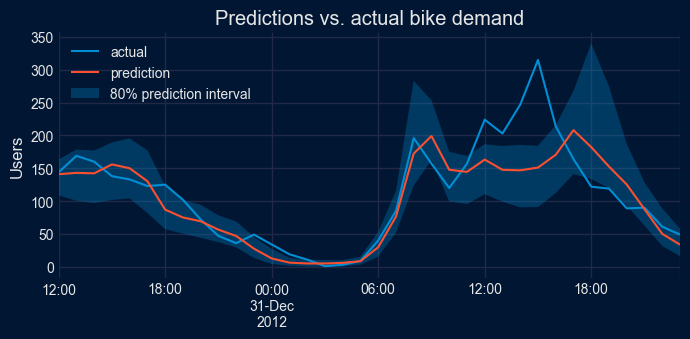

In [19]:
# Plot predictions vs. actual values for the held-out test period
# ==============================================================================
set_dark_theme()
preds = results_eval.predictions
fig, ax = plt.subplots(figsize=(7, 3.5))
data.set_index('date_time').loc[preds.index, 'users'].plot(ax=ax, label='actual')
preds['pred'].plot(ax=ax, label='prediction')
if {'lower_bound', 'upper_bound'}.issubset(preds.columns):
    ax.fill_between(
        preds.index, preds['lower_bound'], preds['upper_bound'],
        alpha=0.3, label='80% prediction interval'
    )
ax.set_title('Predictions vs. actual bike demand')
ax.set_ylabel('Users')
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
# Ask the assistant to interpret the forecast results
# ==============================================================================
answer = assistant.ask(
    prompt  = "Explain the results of this forecast, including the metrics and predictions.",
    context = results_eval
)
answer.show_explanation()

/var/folders/wt/8tvn563d5v55nspfbydgqb9r0000gp/T/ipykernel_87469/3255811032.py:3: DataSentToLLMWarning: `send_data_to_llm=False` does not apply to `context`: the predicted values it carries are sent to the LLM, because a question about a result cannot be answered from summary statistics alone. Your input data is not sent: the observed values that the predictions of a backtest carry (`y_true`) are left out, and a result holds no other value of the data it was fitted on. To keep predictions local, ask without `context`.
  answer = assistant.ask(


╭────────────────────────────────── Assistant Response ──────────────────────────────────╮
│                                                                                        │
│  The model's hold-out error over the 36 hourly steps is a mean absolute error of       │
│  27.682061 users, and its MASE of 0.429918 is below 1, so it beat the one-step naive   │
│  forecast (repeat the previous value) on this window. This is a hold-out evaluation    │
│  on dates already in the data, not a forecast of the future. The model was trained up  │
│  to 2012-12-30 11:00:00 and scored on the next 36 hours.                               │
│                                                                                        │
│  Setup being evaluated                                                                 │
│                                                                                        │
│   • ForecasterRecursive with LGBMRegressor, forecasting users 36 steps ahead at        │
│     hourly frequency.                                                                  │
│   • Inputs: 20 lags, rolling mean and std window features, and the exogenous columns   │
│     holiday, weather and temp (weather is categorical and handled automatically).      │
│   • The lags and window features were suggested by an LLM refinement step. They are    │
│     hypotheses, not validated improvements.                                            │
│   • Prediction intervals use bootstrapping with an 80% nominal level (quantiles 0.1    │
│     and 0.9).                                                                          │
│                                                                                        │
│  Metrics                                                                               │
│                                                                                        │
│   • MAE, 27.682061: the average absolute miss, in units of users. This is the primary  │
│     metric for the plan.                                                               │
│   • RMSE, 41.672254: also in units of users. It is reported alongside MAE, but I       │
│     can't say anything further about the error distribution from these two numbers     │
│     alone.                                                                             │
│   • MASE, 0.429918: below 1, so the model beat the one-step naive forecast on this     │
│     window.                                                                            │
│   • MAPE, 0.383013: a fraction, quoted as given. The target's minimum is 1, so values  │
│     near zero make MAPE unreliable here. I would lean on MAE, RMSE and MASE instead.   │
│                                                                                        │
│  Predictions                                                                           │
│                                                                                        │
│  Only the first 5 and last 5 of the 36 rows were provided, so I won't describe a       │
│  trend across the horizon. Over all 36 rows:                                           │
│                                                                                        │
│   • Point predictions range from 5.065354 to 208.092608, with a mean of 101.619250.    │
│   • The lower bound has a mean of 69.115761 (range 0.320592 to 163.187113).            │
│   • The upper bound has a mean of 139.768766 (range 9.997289 to 340.043089).           │
│                                                                                        │
│  Limitations                                                                           │
│                                                                                        │
│   • Interval coverage and mean interval width were not supplied, so I can't say        │
│     whether the 80% intervals actually contained about 80% of the observed values.   

### Prediction mode

In prediction mode, the model trains on the entire dataset and forecasts the next `steps` time points. Because the data includes exogenous variables (`holiday`, `weather`, `temp`), their future values must be supplied via the `exog` argument.

In [21]:
# Forecast the next 36 hours using the entire dataset (prediction mode)
# ==============================================================================
# Simulate future values of exogenous variables for the next 36 hours
exog = data[['holiday', 'weather', 'temp']].tail(36).copy()
exog.index = pd.date_range(
    start=pd.to_datetime(data['date_time'].max()) + pd.Timedelta(1, unit='h'),
    periods=36,
    freq='h'
)

results_pred = assistant.forecast(
    data        = data,
    steps       = 36,
    interval    = [0.1, 0.9],
    test_size   = None,        # Use the entire dataset (prediction mode)
    exog        = exog,        # Future values of exogenous variables
    profile     = profile,
    plan        = plan_refined
)

display(results_pred.predictions.head())

,pred,lower_bound,upper_bound
2013-01-01 00:00:00,21.122524,13.812877,33.172653
2013-01-01 01:00:00,12.348644,3.750090,26.199809
2013-01-01 02:00:00,9.221664,3.831727,19.045463
2013-01-01 03:00:00,5.183875,0.997964,12.502876
2013-01-01 04:00:00,5.351029,1.011118,11.155282


In [22]:
# Full results object
# ==============================================================================
results_pred

                          Dataset Profile                          
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property       ┃ Value                                          ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Format         │ single                                         │
├────────────────┼────────────────────────────────────────────────┤
│ Series         │ 1                                              │
├────────────────┼────────────────────────────────────────────────┤
│ Observations   │ 17544                                          │
├────────────────┼────────────────────────────────────────────────┤
│ Frequency      │ h                                              │
├────────────────┼────────────────────────────────────────────────┤
│ Target         │ users                                          │
├────────────────┼────────────────────────────────────────────────┤
│ Exog columns   │ holiday, weather, temp  (categorical: weather) │
├────────────────┼────────────────────────────────────────────────┤
│ Missing values │ None                                           │
└────────────────┴────────────────────────────────────────────────┘

                                    Recommendation                                     
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property              ┃ Value                                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task type             │ single_series                                               │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Forecaster            │ ForecasterRecursive                                         │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Forecaster candidates │ ForecasterRecursive, ForecasterDirect, ForecasterFoundation │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Estimator             │ LGBMRegressor                                               │
├───────────────────────┼─────────────────────────────────────────────────────────────┤
│ Estimator candidates  │ LGBMRegressor, XGBRegressor, Ridge                          │
└───────────────────────┴─────────────────────────────────────────────────────────────┘

╭───────────────────────────────── Profile Explanation ──────────────────────────────────╮
│                                                                                        │
│  A single-series ML forecaster (ForecasterRecursive) is recommended. Data: 17544       │
│  observations, 'h' frequency. Alternative forecasters: ['ForecasterDirect',            │
│  'ForecasterFoundation']. Estimator: LGBMRegressor. A gradient boosting model is       │
│  preferred for a dataset of this size (17544 observations). Alternative estimators:    │
│  ['XGBRegressor', 'Ridge']. 3 exogenous variables (1 categorical) available as         │
│  predictors.                                                                           │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯
                                      Forecast Plan                                       
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property          ┃ Value                                                              ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task type         │ single_series                                                      │
├───────────────────┼────────────────────────────────────────────────────────────────────┤
│ Forecaster        │ ForecasterRecursive                                             

### Code-only mode

Use `forecast_code()` when you want to preview or export the reproducible script without executing it. This is useful for code review, auditing the generated pipeline, or running the script in a separate environment.

In [23]:
# Generate the reproducible script without executing it
# ==============================================================================
code_result = assistant.forecast_code(
    data        = data,
    steps       = 36,
    test_size   = 36,
    profile     = profile,
    plan        = plan_refined
)
code_result.show_code()

### The ForecastResult object

Both `forecast()` modes return a `ForecastResult`, a lightweight container that bundles everything the assistant used and produced.

| Attribute | Type | Description |
|---|---|---|
| `predictions` | DataFrame | Forecasted values. When intervals are requested, the bound columns are included alongside the point predictions. |
| `metrics` | DataFrame or None | Evaluation metrics, with the columns of a backtest: one per metric (`mean_absolute_error`, `root_mean_squared_error`, `mean_absolute_scaled_error`, `mean_absolute_percentage_error`) and, with several series, `levels`. `None` in prediction mode. |
| `code` | str | The exact standalone **skforecast** script that produced the forecast, ready to run on its own. |
| `profile` | `ForecastingProfile` | The data profile behind the forecast. |
| `plan` | `ForecastPlan` | The detailed configuration that was executed. |

## Backtesting

The backtesting branch uses the same `profile` and `plan` as the forecast branch but evaluates the model's historical performance through time series cross-validation. The key decision is how to configure the `TimeSeriesFold` object, which controls exactly how the historical data is partitioned into successive training and test windows.

skforecast-ai provides three distinct ways to define this validation strategy:

1. **Explicit instantiation (recommended)**: manually construct a `TimeSeriesFold` and pass it directly to `backtest()`. Use this when you already know your exact operational constraints.

2. **Deterministic `create_cv()`**: allow the assistant to derive a sensible `TimeSeriesFold` from the profile and plan using rule-based defaults. You can override individual parameters explicitly.

3. **LLM `create_cv()` (with a prompt)**: describe your deployment use case in natural language. The LLM translates your description into a fully-configured `TimeSeriesFold`, accompanied by an explanation you can audit.

### Define the backtesting strategy

#### Manual TimeSeriesFold

In [24]:
# Create your own TimeSeriesFold object
# ==============================================================================
end_train = '2012-08-31 23:59:00'
cv = TimeSeriesFold(
    steps              = 36,
    initial_train_size = end_train,
    refit              = False,
    verbose            = False
)
cv

TimeSeriesFold(
    initial_train_size    = 2012-08-31 23:59:00,
    steps                 = 36,
    fold_stride           = 36,
    window_size           = None,
    refit                 = False,
    fixed_train_size      = True,
    gap                   = 0,
    skip_folds            = None,
    allow_incomplete_fold = True,
    return_all_indexes    = False,
    verbose               = False,
)

#### Deterministic create_cv()

Only `initial_train_size` is passed here; the rest of the strategy comes from the defaults. The explanation says which values you chose and why each default has its value.

In [25]:
# Let the assistant derive a TimeSeriesFold with rule-based defaults
# ==============================================================================
cv_det = assistant.create_cv(
    profile            = profile,
    plan               = plan_refined,
    initial_train_size = end_train,
)

cv_det

╭───────────────────────────── Cross-Validation Explanation ─────────────────────────────╮
│                                                                                        │
│  Initial training up to 2012-08-31 23:59:00, trained once (no refit), 36-step          │
│  horizon, 82 folds (the last one has only 12 steps). Trained once by default:          │
│  refitting in every fold would multiply the training cost by the 82 folds.             │
│  initial_train_size as requested.                                                      │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯
        Cross-Validation Configuration         
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Parameter             ┃               Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ steps                 │                  36 │
├───────────────────────┼─────────────────────┤
│ initial_train_size    │ 2012-08-31 23:59:00 │
├───────────────────────┼─────────────────────┤
│ refit                 │               False │
├───────────────────────┼─────────────────────┤
│ fixed_train_size      │               False │
├───────────────────────┼─────────────────────┤
│ gap                   │                   0 │
├───────────────────────┼─────────────────────┤
│ fold_stride           │                  36 │
├───────────────────────┼─────────────────────┤
│ skip_folds            │                None │
├───────────────────────┼─────────────────────┤
│ allow_incomplete_fold │                True │
├───────────────────────┼─────────────────────┤
│ n_folds               │                  82 │
├───────────────────────┼─────────────────────┤
│ n_fits                │                   1 │
├───────────────────────┼─────────────────────┤
│ last_fold_steps       │                  12 │
└───────────────────────┴─────────────────────┘
───────────────────────────────────── Generated code ─────────────────────────────────────
from skforecast.model_selection import TimeSeriesFold                                     
                                                                                          
# Time series cross-validation configuration                                              
cv = TimeSeriesFold(                                                                      
    steps              = 36,                                                              
    initial_train_size = '2012-08-31 23:59:00',                                           
    refit              = False,                                                           
)                                                                                         
                                                                                          

#### LLM create_cv() with a natural-language prompt

Rather than manually configuring `TimeSeriesFold` parameters, you can describe your backtesting strategy in natural language and let the assistant translate it into a rigorous cross-validation schema. The [Agentic forecasting guide](./agentic-forecasting.html#backtesting) shows this translation in an animation.

In [26]:
# Let the assistant create the TimeSeriesFold from a natural-language prompt
# ==============================================================================
prompt = (
    "I forecast bike demand 36 hours ahead. "
    "The model should be trained once on all data up to the end of August 2012, 23:59. "
    "Do not refit the model as the window rolls forward."
)
cv_llm = assistant.create_cv(
    profile = profile,
    plan    = plan_refined,
    prompt  = prompt
)

In [27]:
# Cross-validation strategy derived from the prompt
# ==============================================================================
cv_llm

╭───────────────────────────── Cross-Validation Explanation ─────────────────────────────╮
│                                                                                        │
│  Data is hourly from 2011-01-01 00:00. 2011 has 8760 hours. Jan-Aug 2012 (leap year)   │
│  has 244 days, or 5856 hours. Training through 2012-08-31 23:00 therefore gives 14616  │
│  observations, so initial_train_size=14616. This is far above the minimum viable size  │
│  of 372 (max_lag 336). The remaining 2928 hours (Sep-Dec 2012) give about 81 folds of  │
│  36 steps, well over the 2-fold minimum. The user wants the model trained once with    │
│  no refitting, so refit=False. fixed_train_size has no effect without refit, so it     │
│  stays at its default. No deployment delay was mentioned, so gap=0. fold_stride stays  │
│  at the default (equal to steps, 36), so test sets do not overlap. Using 83% of data   │
│  (14616 observations) for initial training, trained once (no refit), 36-step horizon,  │
│  82 folds (the last one has only 12 steps).                                            │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯
 Cross-Validation Configuration  
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Parameter             ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ steps                 │    36 │
├───────────────────────┼───────┤
│ initial_train_size    │ 14616 │
├───────────────────────┼───────┤
│ refit                 │ False │
├───────────────────────┼───────┤
│ fixed_train_size      │ False │
├───────────────────────┼───────┤
│ gap                   │     0 │
├───────────────────────┼───────┤
│ fold_stride           │    36 │
├───────────────────────┼───────┤
│ skip_folds            │  None │
├───────────────────────┼───────┤
│ allow_incomplete_fold │  True │
├───────────────────────┼───────┤
│ n_folds               │    82 │
├───────────────────────┼───────┤
│ n_fits                │     1 │
├───────────────────────┼───────┤
│ last_fold_steps       │    12 │
└───────────────────────┴───────┘
───────────────────────────────────── Generated code ─────────────────────────────────────
from skforecast.model_selection import TimeSeriesFold                                     
                                                                                          
# Time series cross-validation configuration                                              
cv = TimeSeriesFold(                                                                      
    steps              = 36,                                                              
    initial_train_size = 14616,                                                           
    refit              = False,                                                           
)                                                                                         
                                                                                          

In [28]:
# LLM reasoning behind the TimeSeriesFold configuration
# ==============================================================================
print(textwrap.fill(cv_llm.explanation, width=88))

Data is hourly from 2011-01-01 00:00. 2011 has 8760 hours. Jan-Aug 2012 (leap year) has
244 days, or 5856 hours. Training through 2012-08-31 23:00 therefore gives 14616
observations, so initial_train_size=14616. This is far above the minimum viable size of
372 (max_lag 336). The remaining 2928 hours (Sep-Dec 2012) give about 81 folds of 36
steps, well over the 2-fold minimum. The user wants the model trained once with no
refitting, so refit=False. fixed_train_size has no effect without refit, so it stays at
its default. No deployment delay was mentioned, so gap=0. fold_stride stays at the
default (equal to steps, 36), so test sets do not overlap. Using 83% of data (14616
observations) for initial training, trained once (no refit), 36-step horizon, 82 folds
(the last one has only 12 steps).


Since the `prompt` correctly describes the intended use case, the `cv_llm` object returned by `create_cv()` is equivalent to the one we built manually (the same 82 folds; the timestamp is aligned to the hourly frequency). However, it was derived entirely from a natural-language description. The returned `CVResult` carries the splitter as `cv_llm.cv` and, as `cv_llm.explanation`, a description of the choices the assistant made, allowing you to verify that the resulting `TimeSeriesFold` matches your intended strategy before executing the backtest.

### Run the backtest

In [29]:
# Run backtesting, reusing the pre-computed profile and plan
# ==============================================================================
results_backtest = assistant.backtest(
    data        = data,
    cv          = cv,           # TimeSeriesFold, or a CVResult from create_cv()
    interval    = [0.1, 0.9],   # 80% prediction interval
    profile     = profile,      # Reuse the pre-computed profile
    plan        = plan_refined  # Reuse the refined plan
)

results_backtest.show_explanation()
display(results_backtest.metrics)
display(results_backtest.predictions.head())

  0%|          | 0/82 [00:00<?, ?it/s]

/var/folders/wt/8tvn563d5v55nspfbydgqb9r0000gp/T/ipykernel_87469/3887262773.py:3: IntervalCoverageWarning: The prediction interval [0.1, 0.9] has a nominal coverage of 80 %, but only 62.6 % of the 2928 actual values of the backtest fell inside it (more than 2 binomial standard errors for the number of predictions, and at least 5 percentage points, below 80 %). Do not present this interval as covering 80 %: report the coverage measured in the backtest (the `coverage` column of the metrics).
  results_backtest = assistant.backtest(


╭───────────────────────────────── Backtest Explanation ─────────────────────────────────╮
│                                                                                        │
│  Initial training up to 2012-08-31 23:59:00, trained once (no refit), 36-step          │
│  horizon, 82 folds (the last one has only 12 steps). Results: mean_absolute_error:     │
│  48.1383, root_mean_squared_error: 79.2586, mean_absolute_scaled_error: 0.7571,        │
│  mean_absolute_percentage_error: 0.5589. They are measured on 2928 predictions with    │
│  an observed value (n_evaluated). Prediction interval [0.1, 0.9] (nominal coverage 80  │
│  %): 62.6 % of the 2928 actual values fell inside it (coverage: 0.6264), with a mean   │
│  width of 83.5861 in the units of the target (interval_width).                         │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯

,mean_absolute_error,root_mean_squared_error,mean_absolute_scaled_error,mean_absolute_percentage_error,coverage,interval_width,n_evaluated
0,48.138281,79.258594,0.757107,0.558892,0.626366,83.586126,2928


,fold,step,y_true,pred,lower_bound,upper_bound
2012-09-01 00:00:00,0,1,168.0,116.973395,90.516665,142.509589
2012-09-01 01:00:00,0,2,79.0,96.550804,62.958791,120.704363
2012-09-01 02:00:00,0,3,69.0,56.998001,35.026328,79.646127
2012-09-01 03:00:00,0,4,35.0,28.668120,8.758691,49.434241
2012-09-01 04:00:00,0,5,12.0,12.984980,5.246626,25.689067


The plot opens on ten days of October, where the predictions, the actual values and the interval can be told apart. Double-click on it to see the whole test period, from September to December 2012.

In [30]:
# Plot prediction intervals vs real value
# ==============================================================================
predictions = results_backtest.predictions
data_test = data.set_index("date_time").loc[predictions.index, :]

fig = go.Figure([
    go.Scatter(name='Prediction', x=predictions.index, y=predictions['pred'], mode='lines'),
    go.Scatter(
        name='Real value', x=data_test.index, y=data_test['users'], mode='lines',
    ),
    go.Scatter(
        name='Upper Bound', x=predictions.index, y=predictions['upper_bound'], mode='lines',
        marker=dict(color="#444"), line=dict(width=0), showlegend=False
    ),
    go.Scatter(
        name='Lower Bound', x=predictions.index, y=predictions['lower_bound'], marker=dict(color="#444"),
        line=dict(width=0), mode='lines', fillcolor='rgba(68, 68, 68, 0.3)', fill='tonexty', showlegend=False
    )
])
fig.update_layout(
    title="Real value vs predicted in test data",
    xaxis_title="Date time",
    yaxis_title="users",
    width=800,
    height=400,
    margin=dict(l=20, r=20, t=35, b=20),
    hovermode="x",
    legend=dict(orientation="h", yanchor="top", y=1.1, xanchor="left", x=0.001),
    # Initial zoom on x axis betwee 1 oct to 10 oct
    xaxis=dict(range=['2012-10-01', '2012-10-10'])
)
fig.show()

In [31]:
# Ask the assistant to interpret the backtesting results
# ==============================================================================
answer = assistant.ask(
    prompt = (
        "Explain the results of this backtesting, including the strategy, metrics, "
        "and predictions. Is the model good enough to deploy?"
    ),
    context = results_backtest
)
answer.show_explanation()

/var/folders/wt/8tvn563d5v55nspfbydgqb9r0000gp/T/ipykernel_87469/2899763076.py:3: DataSentToLLMWarning: `send_data_to_llm=False` does not apply to `context`: the predicted values it carries are sent to the LLM, because a question about a result cannot be answered from summary statistics alone. Your input data is not sent: the observed values that the predictions of a backtest carry (`y_true`) are left out, and a result holds no other value of the data it was fitted on. To keep predictions local, ask without `context`.
  answer = assistant.ask(


╭────────────────────────────────── Assistant Response ──────────────────────────────────╮
│                                                                                        │
│  The backtest shows a model that beats the one-step naive forecast on point accuracy   │
│  (MASE 0.7571), but its 80% prediction intervals are too narrow (coverage 0.6264).     │
│  Whether it is good enough to deploy depends on an error tolerance for your use case,  │
│  which is not in the context, so I can't make that call. If you need reliable          │
│  uncertainty ranges, the interval calibration is a concern.                            │
│                                                                                        │
│  Strategy                                                                              │
│                                                                                        │
│   • ForecasterRecursive with LGBMRegressor, forecasting 36 hours ahead.                │
│   • The model was trained once on data up to 2012-08-31 23:59:00 and never refit       │
│     (refit False, 1 fit in total). The results therefore reflect a model deployed      │
│     without retraining.                                                                │
│   • The test span runs from 2012-09-01 to 2012-12-31 in 82 non-overlapping folds of    │
│     36 steps. The last fold has only 12 steps.                                         │
│   • The metrics are measured on 2928 predictions that have an observed value.          │
│   • The plan uses 20 lags, window features (means and standard deviations over 3 and   │
│     24 hours, plus a 168-hour mean), calendar features, and the exogenous variables    │
│     holiday, weather and temp.                                                         │
│   • The lag and window choices came from an LLM refinement step and are hypotheses,    │
│     not validated improvements. This backtest measures this one configuration, so it   │
│     cannot show whether that refinement helped.                                        │
│                                                                                        │
│  Point accuracy                                                                        │
│                                                                                        │
│   • MAE is 48.1383 and RMSE is 79.2586, in the units of the target. For scale, the     │
│     target has a mean of 187.8 and a standard deviation of 181.3.                      │
│   • MASE is 0.7571. Below 1 means the model beats the one-step naive forecast (repeat  │
│     the previous value).                                                               │
│   • MAPE is 0.5589, quoted as a fraction. The target's minimum is 1, so near-zero      │
│     values make MAPE hard to interpret. I would lean on MAE and MASE instead.          │
│                                                                                        │
│  Prediction intervals                                                                  │
│                                                                                        │
│   • The interval is [0.1, 0.9], so nominal coverage is 80%. Observed coverage is       │
│     0.6264, meaning 62.6% of actual values fell inside it.                             │
│   • That is below the nominal level, so the intervals appear too narrow and            │
│     understate uncertainty. The mean width is 83.5861.                                 │
│   • Some lower bounds go negative (the minimum is -3.6258784440759078), although the   │
│     target's minimum is 1. If you need non-negative ranges, those bounds would need    │
│     handling downstream.                                                               │
│                                                                                        │
│  Predictions                                                                         

### Code-only mode

Use `backtest_code()` to generate the reproducible backtesting script without executing it.

In [32]:
# Generate the reproducible backtest script without executing it
# ==============================================================================
code_bt = assistant.backtest_code(
    data        = data,
    cv          = cv,
    profile     = profile,
    plan        = plan_refined
)
code_bt.show_code()

### The BacktestResult object

The `backtest()` method returns a `BacktestResult`, a lightweight container that bundles all the backtesting artifacts.

| Attribute | Type | Description |
|---|---|---|
| `predictions` | DataFrame | Full out-of-sample backtest predictions across all folds. |
| `metrics` | DataFrame | Backtesting metrics (`mean_absolute_error`, `root_mean_squared_error`, `mean_absolute_scaled_error`, `mean_absolute_percentage_error`), one row per series, computed across all folds. |
| `cv_config` | dict | Resolved `TimeSeriesFold` parameters for full traceability of the validation strategy. |
| `code` | str | The exact standalone **skforecast** script that reproduces the backtesting workflow. |
| `explanation` | str | Human-readable summary of the backtesting configuration and results. |
| `profile` | `ForecastingProfile` | The data profile behind the backtest. |
| `plan` | `ForecastPlan` | The detailed configuration that was executed. |

In [33]:
# Full results object
# ==============================================================================
results_backtest

╭───────────────────────────────── Backtest Explanation ─────────────────────────────────╮
│                                                                                        │
│  Initial training up to 2012-08-31 23:59:00, trained once (no refit), 36-step          │
│  horizon, 82 folds (the last one has only 12 steps). Results: mean_absolute_error:     │
│  48.1383, root_mean_squared_error: 79.2586, mean_absolute_scaled_error: 0.7571,        │
│  mean_absolute_percentage_error: 0.5589. They are measured on 2928 predictions with    │
│  an observed value (n_evaluated). Prediction interval [0.1, 0.9] (nominal coverage 80  │
│  %): 62.6 % of the 2928 actual values fell inside it (coverage: 0.6264), with a mean   │
│  width of 83.5861 in the units of the target (interval_width).                         │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯
        Cross-Validation Configuration         
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Parameter             ┃               Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ steps                 │                  36 │
├───────────────────────┼─────────────────────┤
│ initial_train_size    │ 2012-08-31 23:59:00 │
├───────────────────────┼─────────────────────┤
│ refit                 │               False │
├───────────────────────┼─────────────────────┤
│ fixed_train_size      │                True │
├───────────────────────┼─────────────────────┤
│ gap                   │                   0 │
├───────────────────────┼─────────────────────┤
│ fold_stride           │                  36 │
├───────────────────────┼─────────────────────┤
│ skip_folds            │                None │
├───────────────────────┼─────────────────────┤
│ allow_incomplete_fold │                True │
├───────────────────────┼─────────────────────┤
│ n_folds               │                  82 │
├───────────────────────┼─────────────────────┤
│ n_fits                │                   1 │
├───────────────────────┼─────────────────────┤
│ last_fold_steps       │                  12 │
└───────────────────────┴─────────────────────┘
                                     Backtest Metrics                                     
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ mean_abso… ┃ root_mean… ┃ mean_abso… ┃ mean_abso… ┃ coverage ┃ interval_… ┃ n_evaluat… ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│    48.1383 │    79.2586 │     0.7571 │     0.5589 │   0.6264 │    83.5861 │      2,928 │
└────────────┴────────────┴────────────┴────────────┴──────────┴────────────┴────────────┘
                             Backtest Predictions (2928 rows)                             
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Index            ┃    fold ┃    step ┃   y_true ┃     pred ┃ lower_bound ┃ upper_bound ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 2012-09-01       │  0.0000 │  1.0000 │ 168.0000 │ 116.9734 │     90.5167 │    142.5096 │
│ 00:00:00         │         │         │          │          │             │             │
├──────────────────┼─────────┼─────────┼──────────┼──────────┼─────────────┼─────────────┤
│ 2012-09-01       │  0.0000 │  2.0000 │  79.0000 │  96.5508 │     62.9588 │    120.7044 │
│ 01:00:00         │         │         │          │          │             │             │
├──────────────────┼─────────┼─────────┼──────────┼──────────┼─────────────┼─────────────┤
│ 2012-09-01       │  0.0000 │  3.0000 │  69.0000 │  56.9980 │     35.0263 │     79.6461 │
│ 02:00:00         │         │         │          │          │             │             │
├──────────────────┼─────────┼─────────┼──────────┼──────────┼─────────────┼─────────────┤
│ 2012-09-01       │  

## Comparing forecaster configurations

Choosing a forecasting model should not rely on intuition alone. Two configurations that look equally reasonable can perform very differently once evaluated on real temporal data. The most reliable approach is to test every candidate under **identical conditions** and compare their metrics.

The `compare()` method does exactly that. It receives a list of candidate configurations, backtests each one using the same `TimeSeriesFold` strategy, and returns a leaderboard ranked by the selected metric.

In the step-by-step path, the key argument is `profile`. Passing the profile computed at the beginning of this tutorial skips profiling entirely and guarantees that every candidate is evaluated against the **same** data profile. Note that `compare()` does not accept a `plan`: each candidate derives its own plan from the shared profile, which is precisely what makes the candidates differ.

Candidates can be provided in two ways:

+ **Automatic candidates (`candidates=None`)**: the assistant builds the comparison set from the `profile.forecaster_candidates` that belong to the same family as the recommended forecaster, so every row is scored on the same thing. For multi-series data, a multi-series forecaster is never ranked against a multivariate one: `ForecasterRecursiveMultiSeries` is compared with `ForecasterFoundation`. This is useful when exploring a new dataset without a predefined shortlist. When `cv` is the `CVResult` of `create_cv()` for a plan that is none of those candidates (a plan refined with another estimator or other lags, for example), that plan runs too, as the row `'Strategy plan'`, and the summary names it.

+ **Explicit candidates (recommended)**: pass a list of `(name, config)` tuples, where `name` labels the row in the leaderboard and `config` holds the same override keys understood by `plan()`: `'forecaster'`, `'estimator'`, `'estimator_kwargs'`, `'lags'`, `'window_features'`, `'use_exog'`, `'differentiation'`, `'calendar_features'`, `'target_transformer'` and `'dropna_from_series'`. This provides full control and makes the resulting table easier to interpret.

For a single series, `compare()` also adds a seasonal naive baseline (`ForecasterEquivalentDate`, which repeats the value of one seasonal period earlier, or the last value when the frequency has none) as one more row, ranked like the others, so the leaderboard shows whether a model beats the simplest reasonable forecast. Pass `baseline=False` to leave it out.

A failed candidate does not stop the comparison. Instead, a `CandidateFailedWarning` is issued, the row records the error and is placed last.

The [Agentic forecasting guide](./agentic-forecasting.html#comparing-forecaster-configurations) shows a comparison in an animation: the candidates run through the same folds, and the leaderboard is a plain sort of the metric.

<div role="note"
    style="background: rgba(0,191,191,.08); border-left: 6px solid #00bfa5;
        border-radius: 6px; padding: 10px 12px; margin: 1em 0;">

<p style="display:flex; align-items:center; font-size:1rem; color:#00bfa5;
        margin:0 0 6px 0; font-weight:600;">
<span style="margin-right:6px; font-size:18px;">💡</span>
<strong style="margin-right:6px; font-size:18px;">Tip</strong>
</p>

<p>

All candidates use the same cross-validation strategy, ensuring a fair comparison. However, the results are only meaningful if the <code>cv</code> setup reflects the real use case where the model will be deployed. For example, if the production system retrains weekly, the backtest should also refit weekly. If the model is expected to forecast 24 hours ahead, the backtest should use a 24-hour horizon.

The evaluation window must also be representative. A period that is too short or dominated by unusual events (holidays, outages, or exceptional peaks) may favor a candidate that performs poorly over time. Define the validation setup carefully before comparing models so the final ranking is reliable.

</p>

</div>

### Automatic candidates

In [34]:
# Compare the forecaster candidates suggested by the profile
# ==============================================================================
results_compare = assistant.compare(
    data        = data,
    cv          = cv,       # Same TimeSeriesFold used in the backtest above
    candidates  = None,     # Candidates suggested by the assistant 
    profile     = profile   # Reuse the pre-computed profile
)

Comparing forecasters:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

In [35]:
# Ranked leaderboard
# ==============================================================================
results_compare.results

,rank,name,forecaster,estimator,mean_absolute_error,root_mean_squared_error,mean_absolute_scaled_error,mean_absolute_percentage_error,n_evaluated
0,1,ForecasterFoundation,ForecasterFoundation,autogluon/chronos-2-small,38.436159,65.048643,0.605517,0.611349,2928
1,2,ForecasterRecursive,ForecasterRecursive,LGBMRegressor,46.312218,74.134214,0.729017,0.472735,2928
2,3,ForecasterDirect,ForecasterDirect,LGBMRegressor,49.298312,77.049481,0.776211,0.499413,2928
3,4,Baseline (seasonal naive),ForecasterEquivalentDate,None,91.668716,150.507112,1.445666,0.912133,2928


In [36]:
# Deterministic summary of the comparison
# ==============================================================================
results_compare.show_explanation()

╭──────────────────────────────── Comparison Explanation ────────────────────────────────╮
│                                                                                        │
│  Compared 4 configurations, ranked ascending by mean_absolute_error. Shared            │
│  cross-validation strategy: Initial training up to 2012-08-31 23:59:00, trained once   │
│  (no refit), 36-step horizon, 82 folds (the last one has only 12 steps).               │
│  ForecasterFoundation is not trained: the window and refit settings do not apply to    │
│  it, each fold forecasts from the observations before it. Each configuration is        │
│  measured on 2928 predictions with an observed value (n_evaluated in the table: a      │
│  count, not a metric, and it does not change the ranking). Best:                       │
│  'ForecasterFoundation' (ForecasterFoundation / autogluon/chronos-2-small) = 38.4362,  │
│  17.0% ahead of 'ForecasterRecursive' (46.3122). All 3 configurations beat the         │
│  baseline 'Baseline (seasonal naive)' (91.6687). The best, 'ForecasterFoundation',     │
│  beats it by 58.1%.                                                                    │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯

### Explicit candidates

In practice, you will often already have a shortlist in mind: a fast baseline, a gradient boosting model, or a variant with a richer feature set. Passing explicit `(name, config)` tuples keeps the comparison focused and makes the resulting leaderboard easy to understand at a glance.

The `config` dictionary accepts the same overrides as `plan()`. Any omitted option falls back to the deterministic recommendation derived from the shared profile, so candidates can remain concise. For example, `{'forecaster': 'ForecasterDirect'}` changes only the forecaster while keeping the recommended estimator, lags, and features.

<div role="alert" style="background: rgba(255,145,0,.08); border-left: 6px solid #ff9100; border-radius: 6px; padding: 10px 12px; margin: 1em 0;">

<p style="display:flex; align-items:center; font-size:1rem; color:#ff9100; margin:0 0 6px 0; font-weight:600;">
    <span style="margin-right:6px; font-size:18px;">⚠️</span>
    <strong style="margin-right:6px; font-size:18px;">Computational cost</strong>
</p>

<p>
Each candidate is backtested independently across all folds, so runtime increases with both the number and complexity of the configurations. Comparing four candidates will take roughly four times as long as running one backtest.

Start with a small set of clearly different options, review the results, and refine from there. Testing many near-identical variants is costly and rarely useful.
</p>

</div>

In [37]:
# Compare an explicit shortlist of configurations
# ==============================================================================
candidates = [
    (
        "ridge_baseline",
        {
            "forecaster": "ForecasterRecursive",
            "estimator" : "Ridge",
            "lags"      : 24,
        }
    ),
    (
        "lgbm_daily_lags",
        {
            "forecaster": "ForecasterRecursive",
            "estimator" : "LGBMRegressor",
            "lags"      : 24,
        }
    ),
    (
        "refined_plan",
        {
            "forecaster"      : plan_refined.forecaster,
            "estimator"       : plan_refined.estimator,
            "lags"            : plan_refined.forecaster_kwargs.get("lags"),
            "window_features" : plan_refined.forecaster_kwargs.get("window_features"),
        }
    ),
    (
        "lgbm_direct",
        {
            "forecaster": "ForecasterDirect",
            "estimator" : "LGBMRegressor",
            "lags"      : 24,
        }
    ),
    (
        "foundation_model",
        {
            "forecaster": "ForecasterFoundation"
        }
    ),
]

results_compare = assistant.compare(
    data        = data,
    cv          = cv,
    candidates  = candidates,  # Specific candidates to compare
    metric      = ['mean_absolute_error', 'mean_absolute_scaled_error'],
    profile     = profile
)

Comparing forecasters:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

The `refined_plan` candidate reuses the forecaster, estimator, lags and window features of the plan produced by `refine_plan()`. This is the recommended way to validate a refined plan: the leaderboard shows whether the extra domain knowledge actually improves the metrics compared to the deterministic baselines. Passing `create_cv(profile=profile, plan=plan_refined)` as `cv` with `candidates=None` does the same with the candidates of the profile: the refined plan is the row `'Strategy plan'`.

When several metrics are requested, all of them are shown as columns but only the **first** one drives the ranking.

In [38]:
# Ranked leaderboard, sorted by the first metric requested
# ==============================================================================
results_compare.results

,rank,name,forecaster,estimator,mean_absolute_error,mean_absolute_scaled_error,n_evaluated
0,1,foundation_model,ForecasterFoundation,autogluon/chronos-2-small,38.436159,0.605517,2928
1,2,refined_plan,ForecasterRecursive,LGBMRegressor,48.138281,0.757107,2928
2,3,lgbm_direct,ForecasterDirect,LGBMRegressor,50.224908,0.790885,2928
3,4,lgbm_daily_lags,ForecasterRecursive,LGBMRegressor,55.517689,0.874763,2928
4,5,Baseline (seasonal naive),ForecasterEquivalentDate,None,91.668716,1.445666,2928
5,6,ridge_baseline,ForecasterRecursive,Ridge,93.145620,1.468844,2928


### Inspect individual candidates

Because every candidate is a full `BacktestResult`, the details of any individual configuration remain available, including its metrics, its predictions and the standalone script that generated them.

In [39]:
# Inspect a specific candidate
# ==============================================================================
candidate = results_compare.candidates['foundation_model']

display(candidate.metrics)
display(candidate.predictions.head())
candidate.show_code()

,mean_absolute_error,mean_absolute_scaled_error,n_evaluated
0,38.436159,0.605517,2928


,level,fold,step,y_true,pred
2012-09-01 00:00:00,users,0,1,168.0,148.059464
2012-09-01 01:00:00,users,0,2,79.0,102.715004
2012-09-01 02:00:00,users,0,3,69.0,66.084412
2012-09-01 03:00:00,users,0,4,35.0,40.878693
2012-09-01 04:00:00,users,0,5,12.0,29.577866


### Reuse the winning configuration

The most useful result of a comparison is often not the leaderboard, but `best_candidate`. It is a complete `BacktestResult` carrying both the winning `profile` and `plan`, so it can be fed back into the step-by-step workflow without manually rebuilding the configuration.

In [40]:
# Winning configuration
# ==============================================================================
print(f"Best candidate: {results_compare.best_name}")
results_compare.best_candidate.plan

Best candidate: foundation_model


                Forecast Plan                 
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property       ┃ Value                     ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Task type      │ foundation                │
├────────────────┼───────────────────────────┤
│ Forecaster     │ ForecasterFoundation      │
├────────────────┼───────────────────────────┤
│ Estimator      │ autogluon/chronos-2-small │
├────────────────┼───────────────────────────┤
│ Steps          │ 36                        │
├────────────────┼───────────────────────────┤
│ Frequency      │ h                         │
├────────────────┼───────────────────────────┤
│ Use exog       │ True                      │
├────────────────┼───────────────────────────┤
│ Interval       │ None                      │
├────────────────┼───────────────────────────┤
│ Primary metric │ mean_absolute_error       │
├────────────────┼───────────────────────────┤
│ Preprocessing  │ 1 step                    │
└────────────────┴───────────────────────────┘

                                   Preprocessing Steps                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Step                    ┃ Reason                                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ handle_categorical_exog │ Categorical exogenous variables detected: ['weather'].       │
│                         │ 'autogluon/chronos-2-small' consumes categorical covariates  │
│                         │ natively, so no encoding is needed.                          │
└─────────────────────────┴──────────────────────────────────────────────────────────────┘

╭─────────────────────────────────── Plan Explanation ───────────────────────────────────╮
│                                                                                        │
│  Plan: ForecasterFoundation + autogluon/chronos-2-small. No lag or window features:    │
│  the foundation model forecasts directly from the raw context window. Exogenous        │
│  variables included. Primary metric: mean_absolute_error, as requested; also           │
│  computed: mean_absolute_scaled_error. The model reads the last 8192 observations of   │
│  the series as context; the series has 17544, so older observations are not used.      │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯

In [41]:
# Produce the final forecast with the winning configuration
# ==============================================================================
results_pred_best = assistant.forecast(
    data        = data,
    steps       = 36,
    interval    = [0.1, 0.9],
    test_size   = None,                                # Prediction mode
    exog        = exog,                                # Future values of exogenous variables
    profile     = results_compare.profile,             # Shared profile
    plan        = results_compare.best_candidate.plan  # Winning plan
)

results_pred_best.show_code()

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

### Explain mode (comparison)

Like any other result, a `ComparisonResult` can be passed to `ask()` as `context` to have the ranking explained. The LLM restates what the leaderboard measured, not why one candidate beat another, and it cannot change the outcome: all metrics and rankings are computed deterministically before it sees the result.

In [42]:
# Ask the assistant to interpret the comparison
# ==============================================================================
answer = assistant.ask(
    prompt = (
        "Explain the comparison results. Is the margin between the top candidates "
        "meaningful, or are they practically equivalent?"
    ),
    context = results_compare
)
answer.show_explanation()

/var/folders/wt/8tvn563d5v55nspfbydgqb9r0000gp/T/ipykernel_87469/2209842622.py:3: DataSentToLLMWarning: `send_data_to_llm=False` does not apply to `context`: the predicted values it carries are sent to the LLM, because a question about a result cannot be answered from summary statistics alone. Your input data is not sent: the observed values that the predictions of a backtest carry (`y_true`) are left out, and a result holds no other value of the data it was fitted on. To keep predictions local, ask without `context`.
  answer = assistant.ask(


╭────────────────────────────────── Assistant Response ──────────────────────────────────╮
│                                                                                        │
│  The ranking is clear on the supplied numbers, but I can't say whether the margin      │
│  between the top candidates is statistically meaningful. Per-fold errors and their     │
│  spread are not in the context, so I can't judge whether the gaps are larger than      │
│  fold-to-fold variation. I also won't call any pair "practically equivalent", because  │
│  that would need information I don't have.                                             │
│                                                                                        │
│  What the leaderboard shows                                                            │
│                                                                                        │
│  All six candidates were scored on the same 2928 predictions with an observed value,   │
│  and the ranking is ascending mean_absolute_error:                                     │
│                                                                                        │
│   • Rank 1, foundation_model (ForecasterFoundation, autogluon/chronos-2-small): MAE    │
│     38.436159, MASE 0.605517.                                                          │
│   • Rank 2, refined_plan (ForecasterRecursive, LGBMRegressor): MAE 48.138281, MASE     │
│     0.757107.                                                                          │
│   • Rank 3, lgbm_direct (ForecasterDirect, LGBMRegressor): MAE 50.224908, MASE         │
│     0.790885.                                                                          │
│   • Rank 4, lgbm_daily_lags (ForecasterRecursive, LGBMRegressor): MAE 55.517689, MASE  │
│     0.874763.                                                                          │
│   • Rank 5, Baseline (seasonal naive) (ForecasterEquivalentDate): MAE 91.668716, MASE  │
│     1.445666.                                                                          │
│   • Rank 6, ridge_baseline (ForecasterRecursive, Ridge): MAE 93.145620, MASE           │
│     1.468844.                                                                          │
│                                                                                        │
│  The MASE column orders the candidates the same way as the MAE column. The target's    │
│  mean is 187.8 and its standard deviation is 181.3, which gives the MAE values a       │
│  scale.                                                                                │
│                                                                                        │
│  Reading the margins                                                                   │
│                                                                                        │
│   • The top four candidates have MASE below 1, so they beat the one-step naive         │
│     forecast (repeat the previous value). The seasonal naive row and ridge_baseline    │
│     have MASE above 1, so they do not.                                                 │
│   • The four leading candidates all beat the Baseline (seasonal naive) row on          │
│     mean_absolute_error. Ridge does not.                                               │
│   • Between the top candidates, the ranking tells you who scored lower, not whether    │
│     the difference would hold on new data. This applies to the first-versus-second     │
│     gap and to the narrower second-versus-third gap alike.                             │
│   • The leaderboard reports what happened, not why, so I can't attribute the ordering  │
│     to any model characteristic.                                                       │
│                                                                                        │
│  A caveat on the comparison                                                          

### The ComparisonResult object

The `compare()` method returns a `ComparisonResult`, which groups the shared setup, the ranked leaderboard, and the individual backtests in a single object.

| Attribute | Type | Description |
|---|---|---|
| `results` | DataFrame | Ranked leaderboard, one row per candidate, sorted best to worst. Columns: `rank`, `name`, `forecaster`, `estimator`, the metric columns, and `error` when at least one candidate failed. |
| `candidates` | dict | Mapping of candidate name to the full `BacktestResult` object. |
| `failures` | dict | Mapping of candidate name to a `CandidateFailure` describing why it failed. Empty when every candidate succeeds. |
| `ranking_metric` | str | Name of the metric used to sort `results`. |
| `cv_config` | dict | Resolved `TimeSeriesFold` parameters plus the resulting `n_folds`, applied identically to every candidate. |
| `profile` | `ForecastingProfile` | The shared data profile behind every candidate. |
| `explanation` | str | Deterministic, human-readable summary of the comparison. |
| `best_name` | str | Name of the top-ranked candidate. |
| `best_candidate` | `BacktestResult` | Top-ranked candidate as a complete `BacktestResult`. |
| `baseline_name` | str, None | Name of the seasonal naive baseline row, or `None` when no baseline was added (multi-series data, `baseline=False`, or a target with missing values or missing timestamps). |

In [43]:
# Full results object
# ==============================================================================
results_compare

╭──────────────────────────────── Comparison Explanation ────────────────────────────────╮
│                                                                                        │
│  Compared 6 configurations, ranked ascending by mean_absolute_error. Shared            │
│  cross-validation strategy: Initial training up to 2012-08-31 23:59:00, trained once   │
│  (no refit), 36-step horizon, 82 folds (the last one has only 12 steps).               │
│  ForecasterFoundation is not trained: the window and refit settings do not apply to    │
│  it, each fold forecasts from the observations before it. Each configuration is        │
│  measured on 2928 predictions with an observed value (n_evaluated in the table: a      │
│  count, not a metric, and it does not change the ranking). Best: 'foundation_model'    │
│  (ForecasterFoundation / autogluon/chronos-2-small) = 38.4362, 20.2% ahead of          │
│  'refined_plan' (48.1383). 4 of 5 configurations beat the baseline 'Baseline           │
│  (seasonal naive)' (91.6687); 'ridge_baseline' does not. The best,                     │
│  'foundation_model', beats it by 58.1%.                                                │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯
                                    Comparison Results                                    
┏━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Index ┃ rank ┃      name ┃ forecast… ┃ estimator ┃ mean_abso… ┃ mean_abs… ┃ n_evaluat… ┃
┡━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ 0     │    1 │ foundati… │ Forecast… │ autogluo… │    38.4362 │    0.6055 │       2928 │
├───────┼──────┼───────────┼───────────┼───────────┼────────────┼───────────┼────────────┤
│ 1     │    2 │ refined_… │ Forecast… │ LGBMRegr… │    48.1383 │    0.7571 │       2928 │
├───────┼──────┼───────────┼───────────┼───────────┼────────────┼───────────┼────────────┤
│ 2     │    3 │ lgbm_dir… │ Forecast… │ LGBMRegr… │    50.2249 │    0.7909 │       2928 │
├───────┼──────┼───────────┼───────────┼───────────┼────────────┼───────────┼────────────┤
│ 3     │    4 │ lgbm_dai… │ Forecast… │ LGBMRegr… │    55.5177 │    0.8748 │       2928 │
├───────┼──────┼───────────┼───────────┼───────────┼────────────┼───────────┼────────────┤
│ 4     │    5 │  Baseline │ Forecast… │       N/A │    91.6687 │    1.4457 │       2928 │
│       │      │ (seasonal │           │           │            │           │            │
│       │      │    naive) │           │           │            │           │            │
├───────┼──────┼───────────┼───────────┼───────────┼────────────┼───────────┼────────────┤
│ 5     │    6 │ ridge_ba… │ Forecast… │     Ridge │    93.1456 │    1.4688 │       2928 │
└───────┴──────┴───────────┴───────────┴───────────┴────────────┴───────────┴────────────┘

## Reproducible code

Every forecast or backtest workflow exposes the standalone skforecast script used to produce its results. This script is strictly deterministic, ensuring identical outputs for a given set of inputs and configurations. You can access the code at any time via the `show_code()` method.

## Free-form Q&A

The `ask()` method is not limited to interpreting workflow objects. Without any `context` attached, it works as a general forecasting knowledge assistant, useful for clarifying methodology, choosing between approaches, or understanding metric trade-offs.

Without a context there is no task type to route on, so only the general `choosing-a-forecaster` skill is sent unless the question mentions a topic (intervals, backtesting, metrics, ...) that pulls in a specific one. Pass `skills=` to pick them yourself; the names sent are recorded in `answer.skills`. See [Skills for the LLM](./skills.html).

In [44]:
# Ask a general forecasting question (no data or result required)
# ==============================================================================
answer = assistant.ask(
    prompt = (
        "For hourly demand with strong daily and weekly seasonality, when should "
        "I prefer a direct forecasting strategy over a recursive one?"
    )
)
answer.show_explanation()

╭────────────────────────────────── Assistant Response ──────────────────────────────────╮
│                                                                                        │
│  Start with a recursive forecaster (ForecasterRecursive) and prefer a direct one       │
│  (ForecasterDirect) when the relationship between predictors and target changes        │
│  significantly across the forecast horizon. Strong daily and weekly seasonality alone  │
│  is not a reason to switch, since a recursive model can use seasonal lags, window      │
│  features, and calendar exogenous variables.                                           │
│                                                                                        │
│  When direct is a good fit                                                             │
│                                                                                        │
│   • Horizon-dependent patterns: if the short-horizon and long-horizon relationships    │
│     differ, one model reused recursively may fit them poorly. Direct trains one        │
│     independent model per step, so each step can learn its own relationship.           │
│   • Error propagation is a concern: recursive predictions feed into later steps, so    │
│     errors can accumulate. Direct models use only observed data at every step.         │
│   • Long horizons: the documentation lists long horizons where patterns change per     │
│     step as the best case for direct.                                                  │
│                                                                                        │
│  When recursive is usually preferable                                                  │
│                                                                                        │
│   • General purpose: it is the documented default and starting point. It trains a      │
│     single model.                                                                      │
│   • Flexible horizon: steps can be chosen at predict time. Direct requires steps at    │
│     initialization.                                                                    │
│   • Lower cost: direct stores one estimator per step, so it uses more memory and       │
│     trains more slowly. Training can be parallelized with n_jobs.                      │
│   • Short-to-medium horizons: these are the cases where recursive is documented as     │
│     the best fit.                                                                      │
│                                                                                        │
│  Both strategies support                                                               │
│                                                                                        │
│   • Lags, window features (RollingFeatures), and exogenous variables, so weekly and    │
│     daily structure can be encoded either way.                                         │
│   • Bootstrapping and conformal prediction intervals.                                  │
│                                                                                        │
│  How to decide for your data                                                           │
│                                                                                        │
│  I can't tell from the question alone whether your demand relationship changes across  │
│  the horizon, and I can't validate that without results. The reliable way to decide    │
│  is empirical:                                                                         │
│                                                                                        │
│   • Use assistant.compare() to choose between a recursive and a direct candidate on    │
│     your data.                                                                         │
│   • Use assistant.backtest() to measure the accuracy of whichever you pick.          

## Summary

This tutorial covered the **step-by-step path** of `skforecast-ai`. Here is a recap of what each stage does and when to use it:

| Step | Method | When to use |
|---|---|---|
| 1. Profile | `profile()` | Always: produces the `ForecastingProfile` required by all downstream methods. |
| 2. Plan | `plan()` | Always: converts the profile into an executable configuration. |
| 3. Refine plan | `refine_plan()` | Optional: use when you want to override specific decisions (deterministic) or inject domain knowledge (LLM). Always evaluate the result. |
| 4a. Forecast | `forecast()` | When you want future predictions or a held-out evaluation in a single execution. |
| 4a. Code only | `forecast_code()` | When you want to preview or export the script without running it. |
| 4b. CV strategy | `create_cv()` | When you want the assistant to derive or translate a `TimeSeriesFold` for you. |
| 4b. Backtest | `backtest()` | When you want to evaluate the model over multiple historical folds. |
| 4b. Code only | `backtest_code()` | When you want to preview or export the backtesting script without running it. |
| 4c. Compare | `compare()` | When you want to rank several configurations under an identical cross-validation strategy and reuse the winner. |
| Any time | `ask()` | When you want an LLM explanation of any intermediate object or result, or a general forecasting Q&A. |

The key advantage of this path is that the `profile` and `plan` are built **once** and reused across both the forecast and backtest branches. This avoids redundant profiling and ensures that both branches use the same modeling configuration. The same profile can also be handed to `compare()`, so every candidate is ranked against the very same data profile.

For a faster alternative that runs the entire pipeline in a single call, see the [fast-path tutorial](./agentic-forecasting.html). For a comprehensive overview of backtesting mechanics, see the [skforecast backtesting user guide](https://skforecast.org/latest/user_guides/backtesting).